# 03 - Analysis: four questions
Each question gets one chart and a short answer. Uses the clean file from notebook 02.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../data/processed/fund_level_clean.csv", parse_dates=["period"])
df = df[df["is_primary_record"]]          # one row per fund per year (no double counting)
latest = df["year"].max()
cur = df[df["year"] == latest]
print("Latest year:", latest, "| funds:", len(cur))

Latest year: 2025 | funds: 77


## Q1. How concentrated is the industry? Share of assets held by the top 10 funds

Top 10 of 77 funds hold 60.0% of assets in 2025
Funds needed to reach 50% of assets: 8


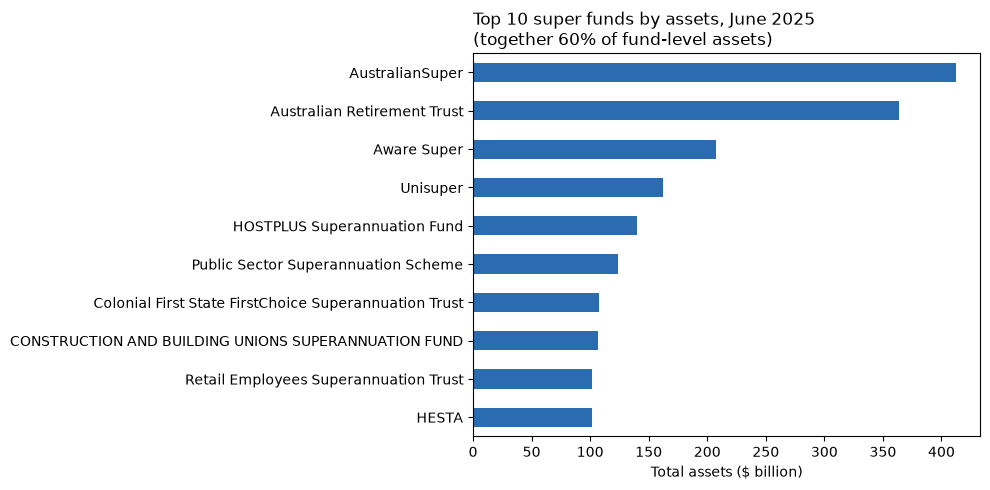

In [2]:
top10 = cur.nlargest(10, "total_assets_k")[["fund_name", "fund_type", "total_assets_k"]]
share = top10["total_assets_k"].sum() / cur["total_assets_k"].sum()
print(f"Top 10 of {len(cur)} funds hold {share:.1%} of assets in {latest}")

ranked = cur["total_assets_k"].dropna().sort_values(ascending=False)
cum = ranked.cumsum() / ranked.sum()
print("Funds needed to reach 50% of assets:", int((cum < 0.5).sum()) + 1)

plot = top10.assign(assets_bn=top10["total_assets_k"] / 1e6).sort_values("assets_bn")
ax = plot.plot.barh(x="fund_name", y="assets_bn", legend=False, figsize=(10, 5), color="#2b6cb0")
ax.set_xlabel("Total assets ($ billion)")
ax.set_ylabel("")
ax.set_title(f"Top 10 super funds by assets, June {latest}\n(together {share:.0%} of fund-level assets)", loc="left")
plt.tight_layout()
plt.savefig("../images/top10_assets.png", dpi=150)
plt.show()

## Q2. How does assets per member differ by fund type?

                 funds  median_assets_per_member  total_assets_bn
fund_type_group                                                  
Corporate            2                  279116.0             36.0
Retail              46                  208652.0            848.0
Public Sector       10                  178905.0            595.0
Industry            19                  105003.0           1566.0


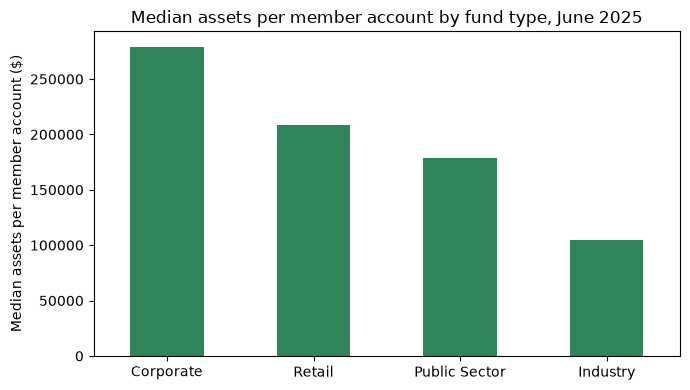

In [3]:
g = (cur.groupby("fund_type_group")
        .agg(funds=("fund_name", "count"),
             median_assets_per_member=("assets_per_member", "median"),
             total_assets_bn=("total_assets_k", lambda s: s.sum() / 1e6))
        .sort_values("median_assets_per_member", ascending=False))
print(g.round(0))

ax = g["median_assets_per_member"].plot.bar(figsize=(7, 4), color="#2f855a", rot=0)
ax.set_ylabel("Median assets per member account ($)")
ax.set_xlabel("")
ax.set_title(f"Median assets per member account by fund type, June {latest}")
plt.tight_layout()
plt.savefig("../images/assets_per_member_by_type.png", dpi=150)
plt.show()

Note: assets per member is **per account**, not per person. One person can have accounts in several funds.
Public sector funds include defined-benefit assets, which push the number up.

## Q3. Do higher-cost funds return more?
Use the 5-year return (less noisy than one year), and only clean rows: 12-month duration, no DQ flag on returns or expenses.

n=68  Pearson r=0.00  Spearman rho=0.16


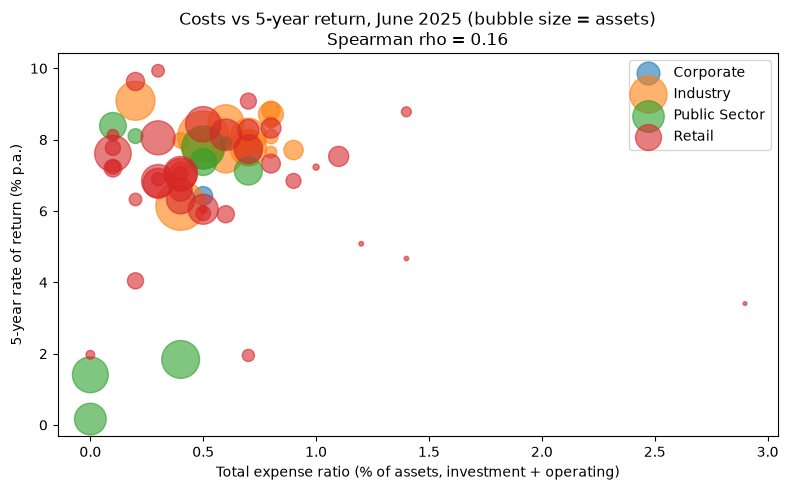

In [4]:
ok = cur[(cur["duration_months"] == 12) & ~cur["chk_return_out_of_range"] & ~cur["chk_expense_ratio_high"]
         & cur["total_expense_ratio"].notna() & cur["return_5y"].notna()]
pearson = ok["total_expense_ratio"].corr(ok["return_5y"])
spearman = ok["total_expense_ratio"].rank().corr(ok["return_5y"].rank())   # Spearman = Pearson on ranks
print(f"n={len(ok)}  Pearson r={pearson:.2f}  Spearman rho={spearman:.2f}")

fig, ax = plt.subplots(figsize=(8, 5))
for t, d in ok.groupby("fund_type_group"):
    ax.scatter(d["total_expense_ratio"] * 100, d["return_5y"] * 100,
               s=np.sqrt(d["total_assets_k"]) / 15, alpha=0.6, label=t)
ax.set_xlabel("Total expense ratio (% of assets, investment + operating)")
ax.set_ylabel("5-year rate of return (% p.a.)")
ax.set_title(f"Costs vs 5-year return, June {latest} (bubble size = assets)\nSpearman rho = {spearman:.2f}")
ax.legend()
plt.tight_layout()
plt.savefig("../images/fees_vs_return.png", dpi=150)
plt.show()

Correlation is not causation. Fund type, the age mix of members (older members tend to be in more conservative options) and fund size all affect both costs and returns.

## Q4. How have assets, member accounts and the number of funds changed over time?

      funds  assets_bn  member_accounts_m  assets_yoy_pct  accounts_yoy_pct
year                                                                       
2014    242     1102.2                NaN             NaN               NaN
2015    232     1233.2               28.0            11.9               NaN
2016    216     1287.7               27.0             4.4              -3.6
2017    198     1612.3               26.4            25.2              -2.1
2018    187     1770.6               25.7             9.8              -2.7
2019    170     1922.1               25.5             8.6              -0.7
2020    157     1928.5               22.5             0.3             -12.0
2021    140     2261.5               21.3            17.3              -5.2
2022    118     2229.0               21.5            -1.4               0.9
2023    107     2456.9               22.3            10.2               3.7
2024     91     2719.4               22.5            10.7               1.1
2025     77 

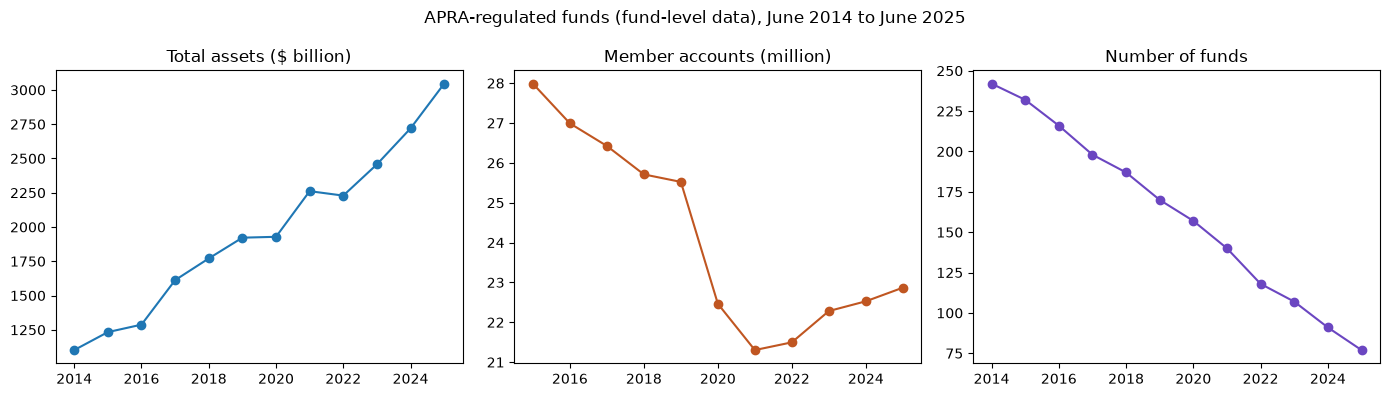

In [5]:
ts = (df.groupby("year")
        .agg(funds=("fund_name", "count"),
             assets_bn=("total_assets_k", lambda s: s.sum() / 1e6),
             member_accounts_m=("member_accounts", lambda s: s.sum(min_count=1) / 1e6)))
ts["assets_yoy_pct"] = (ts["assets_bn"].pct_change() * 100).round(1)
ts["accounts_yoy_pct"] = (ts["member_accounts_m"].pct_change() * 100).round(1)
print(ts.round(1))

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
ts["assets_bn"].plot(ax=axes[0], marker="o", title="Total assets ($ billion)")
ts["member_accounts_m"].plot(ax=axes[1], marker="o", color="#c05621", title="Member accounts (million)")
ts["funds"].plot(ax=axes[2], marker="o", color="#6b46c1", title="Number of funds")
for a in axes:
    a.set_xlabel("")
plt.suptitle("APRA-regulated funds (fund-level data), June 2014 to June " + str(latest))
plt.tight_layout()
plt.savefig("../images/trend.png", dpi=150)
plt.show()

**What the charts show:**
- Assets nearly tripled while the number of funds fell by about two thirds. That's **consolidation** (mergers, pushed by regulators).
- Member accounts fell from about 28m (2015) to about 21m (2021), then rose slightly. The fall is likely linked to reforms that merged lost and inactive duplicate accounts (Protecting Your Super, 2019) and COVID early release in 2020. So fewer accounts doesn't mean fewer people have super.
- Member accounts are blank for 2014 in this file (not reported), so I left that year off the accounts line rather than showing it as zero.
- Big single-year jumps (e.g. 2017) can come from funds entering or leaving the data, not just market growth, so I haven't treated them as pure growth.